# ノイズ(雑音)

ふつう雑音は取り除きたいものですが、わざと作った雑音も役に立ちます。いろいろな周波数をいちどに含むので、回路の周波数特性をまとめて測る試験信号になり、シンセサイザーでは風や波の音のもとになります。雑音には「色」があり、周波数の成分が平らなものを**白色雑音**、低い周波数ほど強いものを**ピンク雑音**といいます。

この回では、白色雑音とピンク雑音の波形と電圧の分布、実効値、そしてスペクトル(周波数ごとの強さ)を見ます。

## 回路

![雑音源](03_noise/circuit.svg)

逆向きに電圧をかけて降伏させたツェナーダイオードには、電子のなだれのような細かい電流のゆらぎがあり、これが雑音になります。R で電流を決め、C で直流を切ってゆらぎだけを取り出し、非反転増幅(1-1)で大きくします。トランジスタの接合を降伏させて同じように使う回路もあります。

## 原理

| | 白色雑音 | ピンク雑音 |
|---|---|---|
| スペクトル | どの周波数も同じ強さ(1 Hz あたり) | 周波数が 2 倍で強さが半分(**−3 dB/oct**、−10 dB/decade) |
| 1 オクターブあたりの強さ | 高いオクターブほど大きい | どのオクターブも同じ |
| 聞こえ方 | 「サー」という高い音 | 「ザー」という落ち着いた音 |

**電圧の分布**:自然の雑音は、たくさんの小さなゆらぎの和なので、山の形(正規分布)になります。Mimic の白色雑音はデジタルの乱数なので、$\pm A$ のあいだに一様に分布します(**実効値 $A/\sqrt{3}$**)。Mimic のピンク雑音は、更新の速さの違う 12 個の乱数を足して作るので、山の形に近くなります(**実効値 $A/3$**)。

**実効値**(rms)は、平均からのずれの 2 乗を平均して平方根をとったもので、雑音の大きさを表すのに使います。直流を除いた電圧の標準偏差と同じです。

**出力のフィルタ**:Mimic は 5 µs ごとに新しい値を出すので、白色雑音は 100 kHz まで平らに広がっています。ところが Mimic の出力には、階段をなめらかにするための約 20 kHz のフィルタがあり、それより高い成分は削られます。オシロで見る白色雑音は、その分だけ実効値が小さくなり、となりあう値が平均されるので、分布も山の形に近づきます。ピンク雑音は大部分が低い周波数にあるので、ほとんど影響を受けません。

測定器のオシロは 20 kHz で取り込むので、10 kHz より上の成分は、折り返して(4-3 のエイリアシング)低い周波数に重なります。白色雑音は折り返しても平らなままです。

![白色雑音とピンク雑音(模式図)](03_noise/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.noise(amp, color)` | `mimic.setNoise(amp, MIMIC_NOISE_WHITE)` など | 振幅 A(V。白色は $\pm A$ の一様、ピンクは実効値 $A/3$)、色 `"white"`、`"pink"` |

- 中心は Vref(2.5 V)です。雑音は入力を使いません。
- 下の準備のセルの `spectrum` は、何回か取り込んで周波数ごとの強さを平均します(雑音のスペクトルは 1 回では大きくばらつくため)。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.4, mimic=20261125)

In [2]:
def show_noise(t, v, label):
    # The first 20 ms of the noise (left) and the distribution of the voltage (right)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw=dict(width_ratios=[2, 1]))
    n = t < 0.02
    ax1.plot(t[n] * 1e3, v[n], color="C1", lw=0.8, label=f"CH2: output ({label})")
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="upper right")
    ax2.hist(v, bins=40, color="C1")
    ax2.set_xlabel("Voltage [V]")
    ax2.set_title("Distribution (0.1 s)")
    plt.tight_layout()
    plt.show()


def spectrum(times=20, points=2000):
    # Power per frequency of the output, averaged over several captures: (Hz, power)
    w = np.hanning(points)
    power = 0
    for _ in range(times):
        t, ch1, ch2 = lab.scope.capture(points)
        power = power + np.abs(np.fft.rfft((ch2 - ch2.mean()) * w))**2
    return np.fft.rfftfreq(points, t[1] - t[0]), power / times

## 実験 1:白色雑音

振幅 1 V の白色雑音を出します。Mimic の中では 1.5〜3.5 V に一様に分布する値(実効値 $1/\sqrt{3}$ = 0.577 V)を 5 µs ごとに作っていますが、出力のフィルタで高い成分が削られるので、オシロで見る実効値はこれより小さく、分布は山の形に近づくはずです。

rms 0.327 V (A / sqrt 3 = 0.577 V), 1.628 - 3.367 V


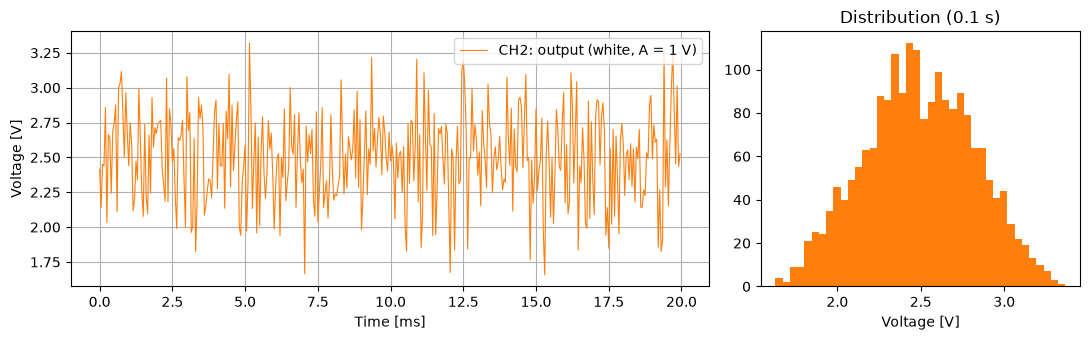

In [3]:
lab.fg.dc(2.5)
lab.mimic.noise(1.0, "white")
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"rms {ch2.std():.3f} V (A / sqrt 3 = {1 / np.sqrt(3):.3f} V), {ch2.min():.3f} - {ch2.max():.3f} V")
show_noise(t, ch2, "white, A = 1 V")

波形は、となりの点との関係がほとんどなく、細かくばらばらに動きます。実効値は 0.33 V ほどで、Mimic の中の値(0.577 V)の 6 割ほどしかありません。分布も平らな箱ではなく、山の形です。Mimic が 5 µs ごとに作る値のうち、出力のフィルタ(約 20 kHz)を通れない速い成分が削られ、となりあう値がならされて平均に近づいたためです(たくさんの値を足し合わせると山の形になる、という中心極限定理の例です)。

## 実験 2:ピンク雑音

振幅 1 V のピンク雑音を出します。分布は山の形になり、実効値は 1/3 = 0.333 V になるはずです。

rms 0.325 V (A / 3 = 0.333 V), 1.528 - 3.488 V


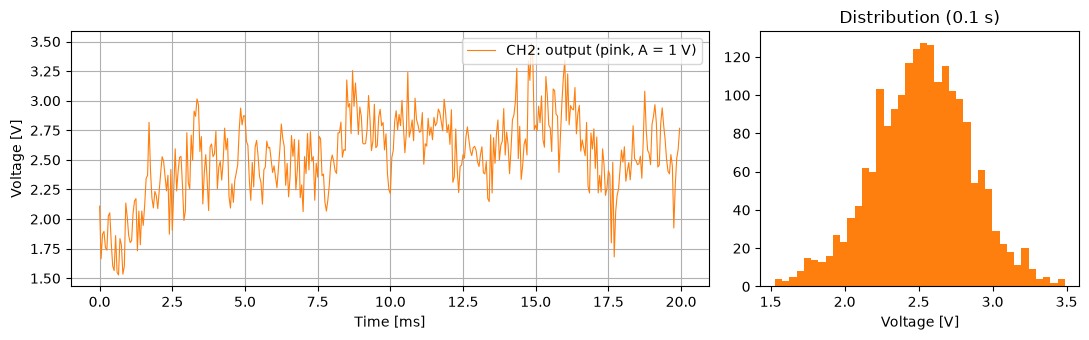

In [4]:
lab.mimic.noise(1.0, "pink")
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"rms {ch2.std():.3f} V (A / 3 = {1 / 3:.3f} V), {ch2.min():.3f} - {ch2.max():.3f} V")
show_noise(t, ch2, "pink, A = 1 V")

ピンク雑音は、低い周波数の成分が強いので、細かいゆらぎに大きなうねりが重なって見えます。0.1 秒の取り込みでは、うねりのために実効値が取り込むたびに少し変わります。

## 実験 3:スペクトル

白色雑音とピンク雑音を、それぞれ 20 回取り込んでスペクトルを平均します。白色は平ら、ピンクは周波数が 10 倍で −10 dB(2 倍で −3 dB)の直線になるはずです。

pink: -9.1 dB / decade = -2.8 dB / octave (theory -10, -3)


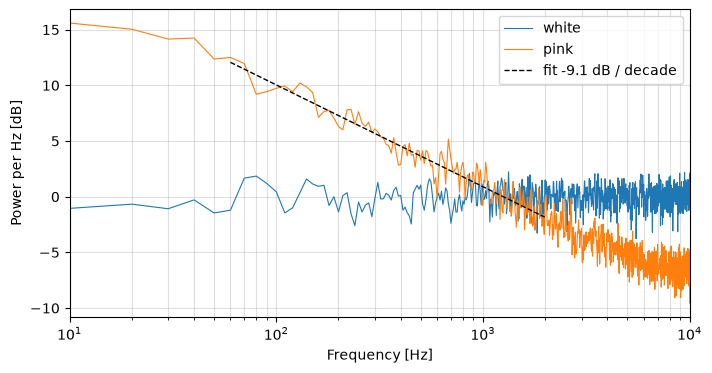

In [5]:
lab.mimic.noise(1.0, "white")
time.sleep(0.1)
f, p_white = spectrum()
lab.mimic.noise(1.0, "pink")
time.sleep(0.1)
f, p_pink = spectrum()

ref = np.median(p_white[1:])
band = (f > 50) & (f < 2000)
slope = np.polyfit(np.log10(f[band]), 10 * np.log10(p_pink[band] / ref), 1)[0]
print(f"pink: {slope:.1f} dB / decade = {slope * np.log10(2):.1f} dB / octave (theory -10, -3)")
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(f[1:], 10 * np.log10(p_white[1:] / ref), lw=0.8, label="white")
ax.semilogx(f[1:], 10 * np.log10(p_pink[1:] / ref), lw=0.8, label="pink")
ax.semilogx(f[band], slope * np.log10(f[band] / 1000) + np.mean(10 * np.log10(p_pink[band] / ref))
            - slope * np.mean(np.log10(f[band] / 1000)), "k--", lw=1, label=f"fit {slope:.1f} dB / decade")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Power per Hz [dB]")
ax.set_xlim(10, 10000)
ax.grid(True, which="both", alpha=0.4)
ax.legend()
plt.show()

白色雑音は全体が平らです。ピンク雑音は直線で下がりますが、5 kHz より上では、測定器で折り返した成分が重なって少し持ち上がります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 振幅を変える
<details><summary>ヒント</summary>

`AMP` を 0.5 → 2.0 → 2.4 → 3.0 と変えてみましょう。白色雑音の実効値は振幅に比例します(0.289、1.155、1.386 V)。3.0 V では、出せる範囲(0.1〜4.9 V)を超えた部分が端に積み上がり、分布の両端に棒が立ちます。`COLOR` を `"pink"` にして同じことを試すと、ピンクは実効値が $A/3$ と小さいので、3.0 V でも端で切れるのはわずかです。

</details>

rms 0.166 V, 2.057 - 2.952 V


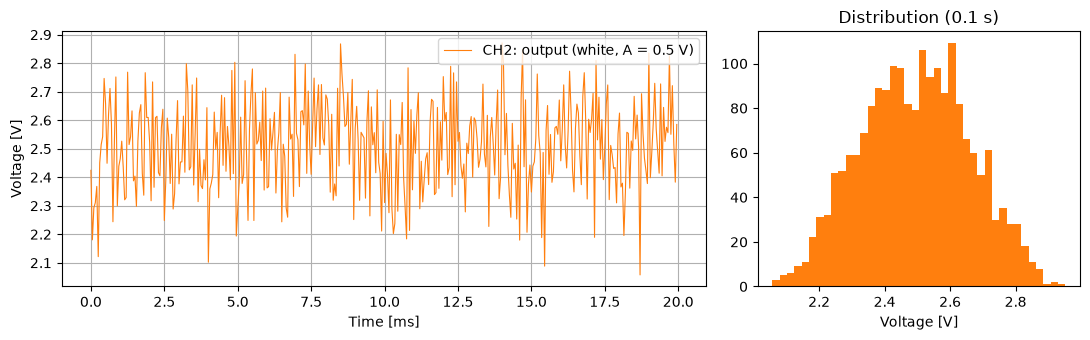

In [6]:
AMP = 0.5          # [V]
COLOR = "white"    # "white" or "pink"

lab.mimic.noise(AMP, COLOR)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"rms {ch2.std():.3f} V, {ch2.min():.3f} - {ch2.max():.3f} V")
show_noise(t, ch2, f"{COLOR}, A = {AMP} V")

### 2. デシメーションで雑音を遅くする

`setDecimation(N)` は、Mimic の処理全体を $2^N$ 倍ゆっくりにします(ライブラリの README)。雑音の更新も $2^N$ 倍ゆっくりになり、高い周波数がなくなります。
<details><summary>ヒント</summary>

`N` を 2 → 4 → 6 と変えてみましょう。白色雑音の更新は 5 µs × $2^N$ ごとになり、高い周波数の成分は、だいたい 100 kHz / $2^N$(25、6.3、1.6 kHz)より上で減っていきます。波形がなめらかになり、スペクトルの右側が下がります。更新が出力のフィルタ(20 kHz)より遅くなるので、分布は Mimic の中の値に近い箱の形に戻っていきます(ただし、デシメーションでは値と値のあいだを直線でつなぐので、少し丸くなります)。**最後に `N = 0` にして実行し、元に戻してください**(最後のセルでも戻します)。

</details>

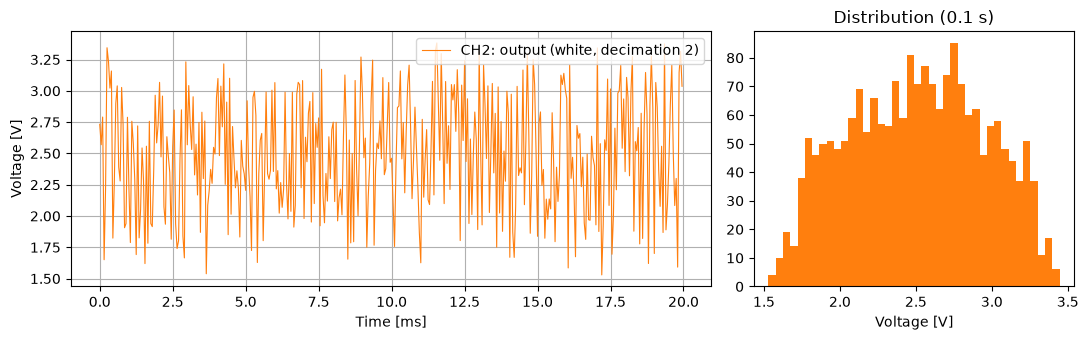

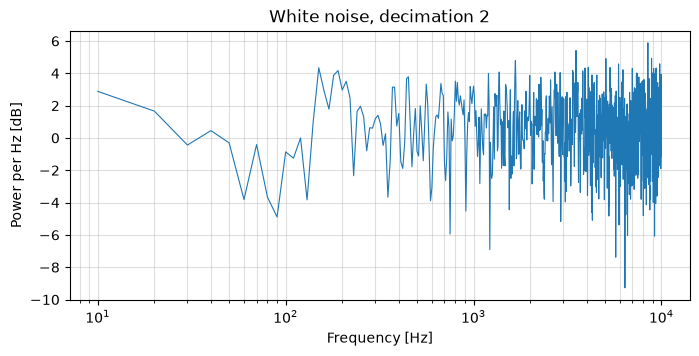

In [7]:
N = 2

lab.mimic.setDecimation(N)
lab.mimic.noise(1.0, "white")
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
show_noise(t, ch2, f"white, decimation {N}")
f, p = spectrum(times=5)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogx(f[1:], 10 * np.log10(p[1:] / np.median(p[1:20])), lw=0.8)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Power per Hz [dB]")
ax.set_title(f"White noise, decimation {N}")
ax.grid(True, which="both", alpha=0.4)
plt.show()

## まとめ

- 雑音には色がある。白色雑音はどの周波数も同じ強さ、ピンク雑音は周波数が 2 倍で −3 dB(どのオクターブも同じ強さ)。
- Mimic の白色雑音は $\pm A$ の一様分布(実効値 $A/\sqrt{3}$)、ピンク雑音は山の形(実効値 $A/3$)。
- 雑音のスペクトルは 1 回ではばらつくので、何回か平均して見る。
- Mimic では `noise(amp, color)`。

最後に Mimic のデシメーションを 0 に戻し、素通し(バイパス)にして、接続を閉じます。

In [8]:
lab.mimic.setDecimation(0)
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()